# Praktikum 5 - Recall dan Waktu Query ANN

**Nama:** Agus

**NIM:** 244107020049

[Sumber modul](https://polinema.gitbook.io/jti-modul-praktikum-pembelajaran-mesin-2025-2026/js06-ann-approximate-nearest-neighbors/praktikum-5)

## Langkah 0 - Persiapan Lingkungan

In [1]:
import sys
import numpy as np
np.random.seed(42)
print("Kernel:", sys.executable)

import faiss
faiss.omp_set_num_threads(4)


Kernel: /Volumes/External/miniconda3/envs/ml-praktikum/bin/python


## Langkah 1 - Import Library

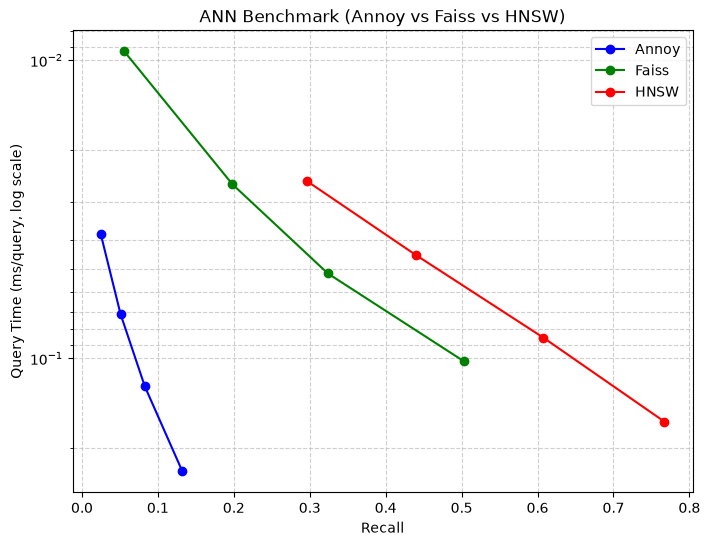

In [2]:
import numpy as np
import time
import faiss
from annoy import AnnoyIndex
import hnswlib
import matplotlib.pyplot as plt

# -------------------------------
# Dataset random
# -------------------------------
d = 128        # dimensi
nb = 100000    # jumlah database vector
nq = 1000      # jumlah query

np.random.seed(42)
xb = np.random.random((nb, d)).astype('float32')
xq = np.random.random((nq, d)).astype('float32')

# -------------------------------
# Ground truth dengan FAISS brute force
# -------------------------------
index_flat = faiss.IndexFlatL2(d)
index_flat.add(xb)
k = 10
_, gt_idx = index_flat.search(xq, k)

# -------------------------------
# Fungsi recall
# -------------------------------
def recall_at_k(I_pred, I_gt, k):
    correct = 0
    for i in range(len(I_pred)):
        correct += len(set(I_pred[i][:k]) & set(I_gt[i][:k]))
    return correct / (len(I_pred) * k)

# -------------------------------
# Benchmark Annoy
# -------------------------------
def run_annoy(xb, xq, n_trees=10, search_k=1000, k=10):
    f = xb.shape[1]
    index = AnnoyIndex(f, 'euclidean')
    for i, v in enumerate(xb):
        index.add_item(i, v)
    index.build(n_trees)

    start = time.time()
    I = [index.get_nns_by_vector(v, k, search_k=search_k) for v in xq]
    elapsed = (time.time() - start) * 1000 / len(xq)  # ms/query
    rec = recall_at_k(I, gt_idx, k)
    return rec, elapsed

# -------------------------------
# Benchmark FAISS IVF
# -------------------------------
def run_faiss(xb, xq, nlist=100, nprobe=10, k=10):
    quantizer = faiss.IndexFlatL2(d)
    index = faiss.IndexIVFFlat(quantizer, d, nlist, faiss.METRIC_L2)
    index.train(xb)
    index.add(xb)

    index.nprobe = nprobe
    start = time.time()
    _, I = index.search(xq, k)
    elapsed = (time.time() - start) * 1000 / len(xq)
    rec = recall_at_k(I, gt_idx, k)
    return rec, elapsed

# -------------------------------
# Benchmark HNSW
# -------------------------------
def run_hnsw(xb, xq, ef=100, M=16, k=10):
    num_elements = xb.shape[0]
    p = hnswlib.Index(space='l2', dim=d)
    p.init_index(max_elements=num_elements, ef_construction=200, M=M)
    p.add_items(xb)
    p.set_ef(ef)

    start = time.time()
    I, _ = p.knn_query(xq, k)
    elapsed = (time.time() - start) * 1000 / len(xq)
    rec = recall_at_k(I, gt_idx, k)
    return rec, elapsed

# -------------------------------
# Jalankan benchmark dengan beberapa parameter
# -------------------------------
results = {"Annoy": [], "Faiss": [], "HNSW": []}

# Annoy
for sk in [200, 500, 1000, 2000]:
    rec, t = run_annoy(xb, xq, n_trees=10, search_k=sk)
    results["Annoy"].append((rec, t))

# FAISS
for npb in [1, 5, 10, 20]:
    rec, t = run_faiss(xb, xq, nlist=100, nprobe=npb)
    results["Faiss"].append((rec, t))

# HNSW
for ef in [50, 100, 200, 400]:
    rec, t = run_hnsw(xb, xq, ef=ef)
    results["HNSW"].append((rec, t))

# -------------------------------
# Visualisasi trade-off
# -------------------------------
plt.figure(figsize=(8,6))
for label, color in zip(results.keys(), ["blue","green","red"]):
    recall, qtime = zip(*results[label])
    plt.plot(recall, qtime, marker="o", label=label, color=color)

plt.xlabel("Recall")
plt.ylabel("Query Time (ms/query, log scale)")
plt.yscale("log")
plt.gca().invert_yaxis()  # invert Y, makin kanan makin turun
plt.title("ANN Benchmark (Annoy vs Faiss vs HNSW)")
plt.legend()
plt.grid(True, which="both", ls="--", alpha=0.6)
plt.show()


## Tabel Hasil dan QPS

Grafik kode modul memakai ms/query dengan sumbu waktu terbalik. QPS dihitung sebagai 1.000 dibagi ms/query; nilainya berasal dari pengukuran query batch, tanpa build index.

,Model,Parameter,Recall@10,ms/query,QPS
0,Annoy,200,0.0248,0.0384,26064.2050
1,Annoy,500,0.0508,0.0710,14075.7903
2,Annoy,1000,0.0828,0.1242,8048.9426
3,Annoy,2000,0.1323,0.2396,4172.7559
4,Faiss,1,0.0558,0.0094,106937.5351
5,Faiss,5,0.1981,0.0261,38359.4959
6,Faiss,10,0.3239,0.0519,19255.5607
7,Faiss,20,0.5031,0.1024,9769.9181
8,HNSW,50,0.2958,0.0254,39387.2043
9,HNSW,100,0.4394,0.0450,22237.6188


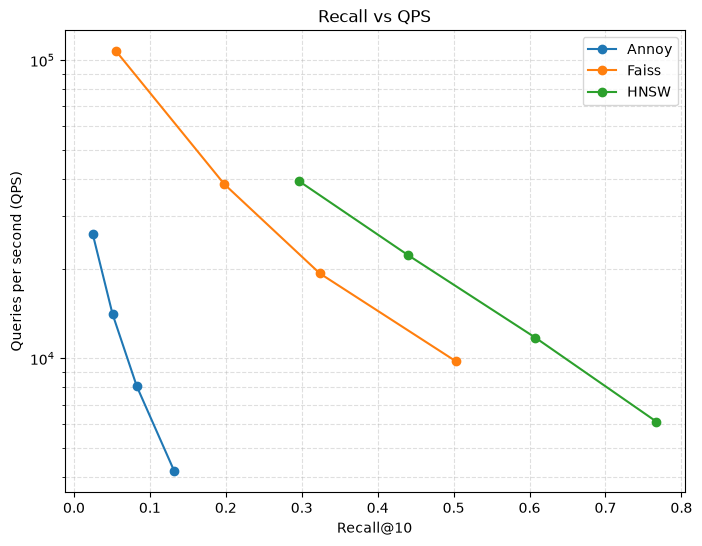

In [3]:
import pandas as pd
from IPython.display import display

parameter_values = {'Annoy': [200, 500, 1000, 2000],
                    'Faiss': [1, 5, 10, 20], 'HNSW': [50, 100, 200, 400]}
benchmark_df = pd.DataFrame([
    {'Model': model, 'Parameter': value, 'Recall@10': rec,
     'ms/query': elapsed, 'QPS': 1000 / elapsed}
    for model, values in results.items()
    for value, (rec, elapsed) in zip(parameter_values[model], values)
])
display(benchmark_df.round(4))
fig, ax = plt.subplots(figsize=(8, 6))
for name, group in benchmark_df.groupby('Model', sort=False):
    ax.plot(group['Recall@10'], group['QPS'], marker='o', label=name)
ax.set(xlabel='Recall@10', ylabel='Queries per second (QPS)', title='Recall vs QPS')
ax.set_yscale('log')
ax.grid(True, which='both', ls='--', alpha=0.4)
ax.legend()
plt.show()


## Analisis

search_k, nprobe, dan ef yang lebih besar memperluas pencarian sehingga recall dapat naik dengan biaya waktu query. Posisi kanan atas pada grafik QPS berarti recall tinggi dan query cepat. Rebuild dilakukan setiap konfigurasi mengikuti kode modul; waktu build tersebut tidak masuk angka ms/query.